# Online Shopping Basket Analysis
## Market Basket Analysis with Apriori and Association Rules

This notebook analyzes grocery purchases and builds a product recommender. Each basket represents one **customer on one date** (`Member_number + Date`). Place `Dataset14-Grocery-MarketBasket-Analysis.csv` beside this notebook, then run cells from top to bottom.

**Workflow:** load and clean data → customer-day baskets → Apriori itemsets and rules → recommendations → customer validation → export results.


## 1. Install required libraries
Run once in this notebook environment. Skip if already installed.

In [1]:
%pip install -q pandas numpy matplotlib seaborn mlxtend


Note: you may need to restart the kernel to use updated packages.


## 2. Import libraries

In [2]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display
from mlxtend.frequent_patterns import apriori, association_rules
sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")


Libraries imported successfully.


## 3. Load dataset
Expected columns: `Member_number`, `Date`, and `itemDescription`. Keep the CSV beside this notebook or update `DATA_FILE`.

In [3]:
DATA_FILE = r"C:\Users\HP\Desktop\Online-Shopping-Basket-Analysis\dataset\Dataset14-Grocery-MarketBasket-Analysis.csv"
df = pd.read_csv(DATA_FILE)
df.columns = df.columns.str.strip()

required_columns = {"Member_number", "Date", "itemDescription"}
missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

print(f"Dataset loaded: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

Dataset loaded: 38,765 rows × 3 columns


,Member_number,Date,itemDescription
0,1808,21-07-2015,tropical fruit
1,2552,05-01-2015,whole milk
2,2300,19-09-2015,pip fruit
3,1187,12-12-2015,other vegetables
4,3037,01-02-2015,whole milk


## 4. Inspect and clean data

In [4]:
print("Shape:", df.shape)
print("\nColumn types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())


Shape: (38765, 3)

Column types:
Member_number      int64
Date                 str
itemDescription      str
dtype: object

Missing values:
Member_number      0
Date               0
itemDescription    0
dtype: int64

Duplicate rows: 759


In [5]:
df = df.drop_duplicates().dropna(subset=["Member_number", "Date", "itemDescription"]).copy()
df["itemDescription"] = df["itemDescription"].astype(str).str.strip().str.lower()
df = df[df["itemDescription"].ne("")].copy()
print("Rows after cleaning:", f"{len(df):,}")


Rows after cleaning: 38,006


## 5. Process dates

In [6]:
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")
df = df.dropna(subset=["Date"]).copy()
df["Date"] = df["Date"].dt.normalize()
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())


Date range: 2014-01-01 to 2015-12-30


## 6. Explore customers and products

In [7]:
print("Unique customers:", f"{df['Member_number'].nunique():,}")
print("Unique products:", f"{df['itemDescription'].nunique():,}")
product_counts = df["itemDescription"].value_counts()
display(product_counts.head(20).rename("Purchase records").to_frame())


Unique customers: 3,898
Unique products: 167


,Purchase records
itemDescription,
whole milk,2363
other vegetables,1827
rolls/buns,1646
soda,1453
yogurt,1285
root vegetables,1041
tropical fruit,1014
bottled water,908
sausage,903


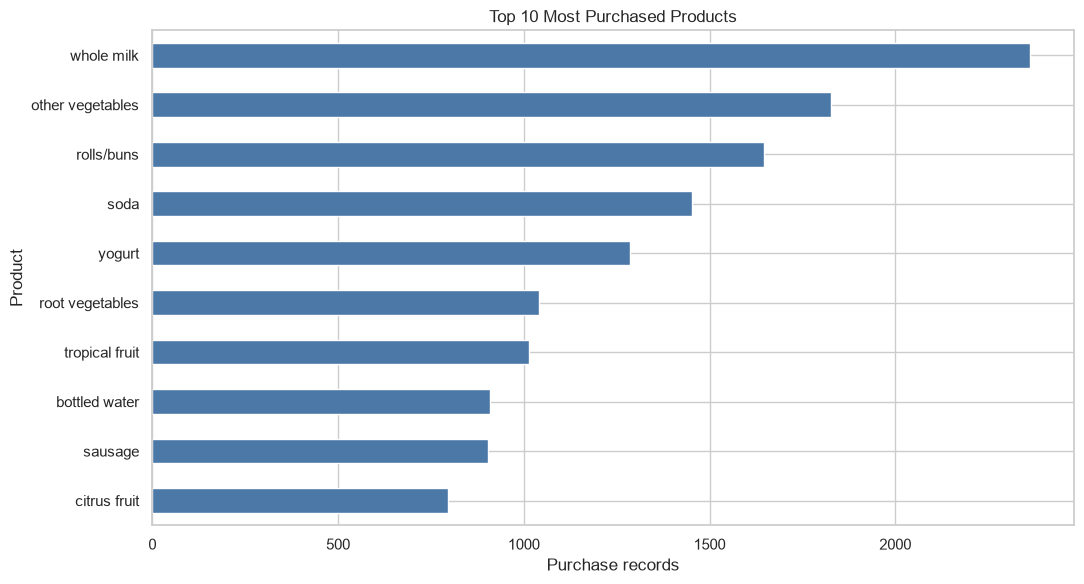

In [8]:
plt.figure(figsize=(11, 6))
product_counts.head(10).sort_values().plot(kind="barh", color="#4C78A8")
plt.title("Top 10 Most Purchased Products")
plt.xlabel("Purchase records")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


## 7. Create customer-day baskets
Each basket is identified by `Member_number + Date`; another date for the same customer is a separate basket.

In [9]:
df["Basket_ID"] = df["Member_number"].astype(str) + "_" + df["Date"].dt.strftime("%Y-%m-%d")
display(df[["Member_number", "Date", "itemDescription", "Basket_ID"]].head(10))
print("Total customer-day baskets:", f"{df['Basket_ID'].nunique():,}")


,Member_number,Date,itemDescription,Basket_ID
0,1808,2015-07-21,tropical fruit,1808_2015-07-21
1,2552,2015-01-05,whole milk,2552_2015-01-05
2,2300,2015-09-19,pip fruit,2300_2015-09-19
3,1187,2015-12-12,other vegetables,1187_2015-12-12
4,3037,2015-02-01,whole milk,3037_2015-02-01
5,4941,2015-02-14,rolls/buns,4941_2015-02-14
6,4501,2015-05-08,other vegetables,4501_2015-05-08
7,3803,2015-12-23,pot plants,3803_2015-12-23
8,2762,2015-03-20,whole milk,2762_2015-03-20
9,4119,2015-02-12,tropical fruit,4119_2015-02-12


Total customer-day baskets: 14,963


## 8. Build and encode basket matrix

In [10]:
basket_matrix = pd.crosstab(df["Basket_ID"], df["itemDescription"])
basket_trans = basket_matrix.gt(0).astype("int8")
print("Basket matrix:", basket_trans.shape[0], "baskets ×", basket_trans.shape[1], "products")
display(basket_trans.head())


Basket matrix: 14963 baskets × 167 products


itemDescription,abrasive cleaner,artif. sweetener,baby cosmetics,bags,baking powder,bathroom cleaner,beef,berries,beverages,bottled beer,...,uht-milk,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
Basket_ID,,,,,,,,,,,,,,,,,,,,,
1000_2014-06-24,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
1000_2015-03-15,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,1,0
1000_2015-05-27,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1000_2015-07-24,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1000_2015-11-25,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## 9. Product frequency by basket

In [11]:
product_frequency = basket_trans.sum(axis=0).sort_values(ascending=False)
display(product_frequency.head(20).rename("Baskets containing product").to_frame())


,Baskets containing product
itemDescription,
whole milk,2363
other vegetables,1827
rolls/buns,1646
soda,1453
yogurt,1285
root vegetables,1041
tropical fruit,1014
bottled water,908
sausage,903


## 10. Apriori frequent itemsets
`min_support=0.01` requires an itemset to appear in at least 1% of baskets. Adjust this threshold to change the number of results.

In [12]:
# Customer-day basket support is lower than item support, so use a threshold
# that retains meaningful co-occurrences for this dataset.
MIN_SUPPORT = 0.001
frequent_itemsets = apriori(basket_trans, min_support=MIN_SUPPORT, use_colnames=True, low_memory=True)
frequent_itemsets = frequent_itemsets.sort_values("support", ascending=False).reset_index(drop=True)
print("Frequent itemsets:", f"{len(frequent_itemsets):,}")
display(frequent_itemsets.head(20))


Frequent itemsets: 750


C:\Users\HP\Desktop\Online-Shopping-Basket-Analysis\.venv\Lib\site-packages\mlxtend\frequent_patterns\fpcommon.py:175: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


,support,itemsets
0,0.157923,frozenset({whole milk})
1,0.122101,frozenset({other vegetables})
2,0.110005,frozenset({rolls/buns})
3,0.097106,frozenset({soda})
4,0.085879,frozenset({yogurt})
5,0.069572,frozenset({root vegetables})
6,0.067767,frozenset({tropical fruit})
7,0.060683,frozenset({bottled water})
8,0.060349,frozenset({sausage})
9,0.053131,frozenset({citrus fruit})


## 11. Generate association rules
Confidence measures how often the consequent appears with the antecedent. Lift above 1 indicates positive association relative to independent purchases.

In [13]:
if frequent_itemsets.empty:
    rules = pd.DataFrame()
else:
    # Generate all rules first; recommendation thresholds are applied later.
    # Filtering on lift here can discard valid rules before they are usable.
    rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.0)
if rules.empty:
    print("No association rules were generated. Try lowering MIN_SUPPORT.")
    rules_sorted = rules.copy()
else:
    rules_sorted = rules.sort_values(["lift", "confidence", "support"], ascending=False).reset_index(drop=True)
    print("Association rules:", f"{len(rules_sorted):,}")
    display(rules_sorted[["antecedents", "consequents", "support", "confidence", "lift"]].head(20))


Association rules: 1,238


,antecedents,consequents,support,confidence,lift
0,"frozenset({yogurt, whole milk})",frozenset({sausage}),0.001470,0.131737,2.182917
1,frozenset({sausage}),"frozenset({yogurt, whole milk})",0.001470,0.024363,2.182917
2,"frozenset({whole milk, sausage})",frozenset({yogurt}),0.001470,0.164179,1.911760
3,frozenset({yogurt}),"frozenset({whole milk, sausage})",0.001470,0.017121,1.911760
4,frozenset({specialty chocolate}),frozenset({citrus fruit}),0.001403,0.087866,1.653762
5,frozenset({citrus fruit}),frozenset({specialty chocolate}),0.001403,0.026415,1.653762
6,"frozenset({yogurt, sausage})",frozenset({whole milk}),0.001470,0.255814,1.619866
7,frozenset({whole milk}),"frozenset({yogurt, sausage})",0.001470,0.009310,1.619866
8,frozenset({tropical fruit}),frozenset({flour}),0.001069,0.015779,1.617141
9,frozenset({flour}),frozenset({tropical fruit}),0.001069,0.109589,1.617141


## 12. Readable association rules

In [14]:
def format_itemset(itemset):
    return ", ".join(sorted(itemset))
rules_display = rules_sorted.copy()
if not rules_display.empty:
    rules_display["antecedents"] = rules_display["antecedents"].apply(format_itemset)
    rules_display["consequents"] = rules_display["consequents"].apply(format_itemset)
    display(rules_display[["antecedents", "consequents", "support", "confidence", "lift"]].head(20))


,antecedents,consequents,support,confidence,lift
0,"whole milk, yogurt",sausage,0.001470,0.131737,2.182917
1,sausage,"whole milk, yogurt",0.001470,0.024363,2.182917
2,"sausage, whole milk",yogurt,0.001470,0.164179,1.911760
3,yogurt,"sausage, whole milk",0.001470,0.017121,1.911760
4,specialty chocolate,citrus fruit,0.001403,0.087866,1.653762
5,citrus fruit,specialty chocolate,0.001403,0.026415,1.653762
6,"sausage, yogurt",whole milk,0.001470,0.255814,1.619866
7,whole milk,"sausage, yogurt",0.001470,0.009310,1.619866
8,tropical fruit,flour,0.001069,0.015779,1.617141
9,flour,tropical fruit,0.001069,0.109589,1.617141


## 13. Product recommendation function
Recommendations are ranked by lift, confidence, and support, with one row per suggested product.

In [15]:
def recommend_products(product, rules_df, min_confidence=0.10, min_lift=1.0, top_n=10):
    product = str(product).strip().lower()
    columns = ["Product", "Support", "Confidence", "Lift"]
    if rules_df is None or rules_df.empty:
        return pd.DataFrame(columns=columns)
    matches = rules_df[rules_df["antecedents"].apply(lambda items: product in set(items))].copy()
    matches = matches[(matches["confidence"] >= min_confidence) & (matches["lift"] >= min_lift)]
    rows = []
    for _, row in matches.iterrows():
        for item in row["consequents"]:
            if item != product:
                rows.append({"Product": item, "Support": row["support"], "Confidence": row["confidence"], "Lift": row["lift"]})
    if not rows:
        return pd.DataFrame(columns=columns)
    return (pd.DataFrame(rows)
            .sort_values(["Lift", "Confidence", "Support"], ascending=False)
            .drop_duplicates("Product")
            .head(top_n)
            .reset_index(drop=True))


## 14. Test recommendations for common products

In [16]:
for product in ["whole milk", "yogurt", "rolls/buns", "other vegetables"]:
    print(f"\nRecommendations for {product}:")
    result = recommend_products(product, rules, min_confidence=0.10, min_lift=1.0, top_n=10)
    if result.empty:
        print("No recommendations met the current thresholds.")
    else:
        display(result)



Recommendations for whole milk:


,Product,Support,Confidence,Lift
0,sausage,0.001470,0.131737,2.182917
1,yogurt,0.001470,0.164179,1.911760
2,soda,0.001069,0.119403,1.229612
3,rolls/buns,0.001136,0.126866,1.153275



Recommendations for yogurt:


,Product,Support,Confidence,Lift
0,sausage,0.001470,0.131737,2.182917
1,whole milk,0.001470,0.255814,1.619866
2,rolls/buns,0.001337,0.119760,1.088685



Recommendations for rolls/buns:


,Product,Support,Confidence,Lift
0,whole milk,0.001136,0.212500,1.345594
1,other vegetables,0.001136,0.140496,1.150651
2,soda,0.001136,0.107595,1.108013



Recommendations for other vegetables:


,Product,Support,Confidence,Lift
0,soda,0.001136,0.107595,1.108013
1,rolls/buns,0.001136,0.117241,1.065785


## 15. Interactive recommendation
Enter an exact product name. If interactive input is unavailable in your notebook environment, assign `product_name` directly and run the rest of this cell.

In [17]:
# Use a deterministic example so Run All never blocks on input().
product_name = "sausage"
if product_name not in basket_trans.columns:
    print("Product not found. Check spelling and use a product from the dataset.")
else:
    interactive_recommendations = recommend_products(product_name, rules, min_confidence=0.10, min_lift=1.0)
    print(f"\nRecommendations for: {product_name}")
    if interactive_recommendations.empty:
        print("No strong recommendations found with the current thresholds.")
    else:
        display(interactive_recommendations)



Recommendations for: sausage


,Product,Support,Confidence,Lift
0,yogurt,0.001470,0.164179,1.911760
1,whole milk,0.001470,0.255814,1.619866
2,soda,0.001069,0.119403,1.229612
3,rolls/buns,0.001136,0.126866,1.153275


## 16. Whole-milk rules and visualization
Show the strongest global rules where whole milk occurs in either the antecedent or consequent.

In [18]:
whole_milk = "whole milk"
if whole_milk not in basket_trans.columns:
    print("whole milk is not present in this dataset.")
    whole_milk_rules = pd.DataFrame()
else:
    whole_milk_rules = rules_sorted[
        rules_sorted["antecedents"].apply(lambda x: whole_milk in x) |
        rules_sorted["consequents"].apply(lambda x: whole_milk in x)
    ].head(10).copy()
    if whole_milk_rules.empty:
        print("No whole-milk rules at the current support threshold.")
    else:
        whole_milk_display = whole_milk_rules.copy()
        whole_milk_display["Rule"] = (whole_milk_display["antecedents"].apply(format_itemset) + " → " + whole_milk_display["consequents"].apply(format_itemset))
        display(whole_milk_display[["Rule", "support", "confidence", "lift"]])


,Rule,support,confidence,lift
0,"whole milk, yogurt → sausage",0.001470,0.131737,2.182917
1,"sausage → whole milk, yogurt",0.001470,0.024363,2.182917
2,"sausage, whole milk → yogurt",0.001470,0.164179,1.911760
3,"yogurt → sausage, whole milk",0.001470,0.017121,1.911760
6,"sausage, yogurt → whole milk",0.001470,0.255814,1.619866
7,"whole milk → sausage, yogurt",0.001470,0.009310,1.619866
12,"sausage → soda, whole milk",0.001069,0.017719,1.523708
13,"soda, whole milk → sausage",0.001069,0.091954,1.523708
34,"rolls/buns, whole milk → sausage",0.001136,0.081340,1.347825
35,"sausage → rolls/buns, whole milk",0.001136,0.018826,1.347825


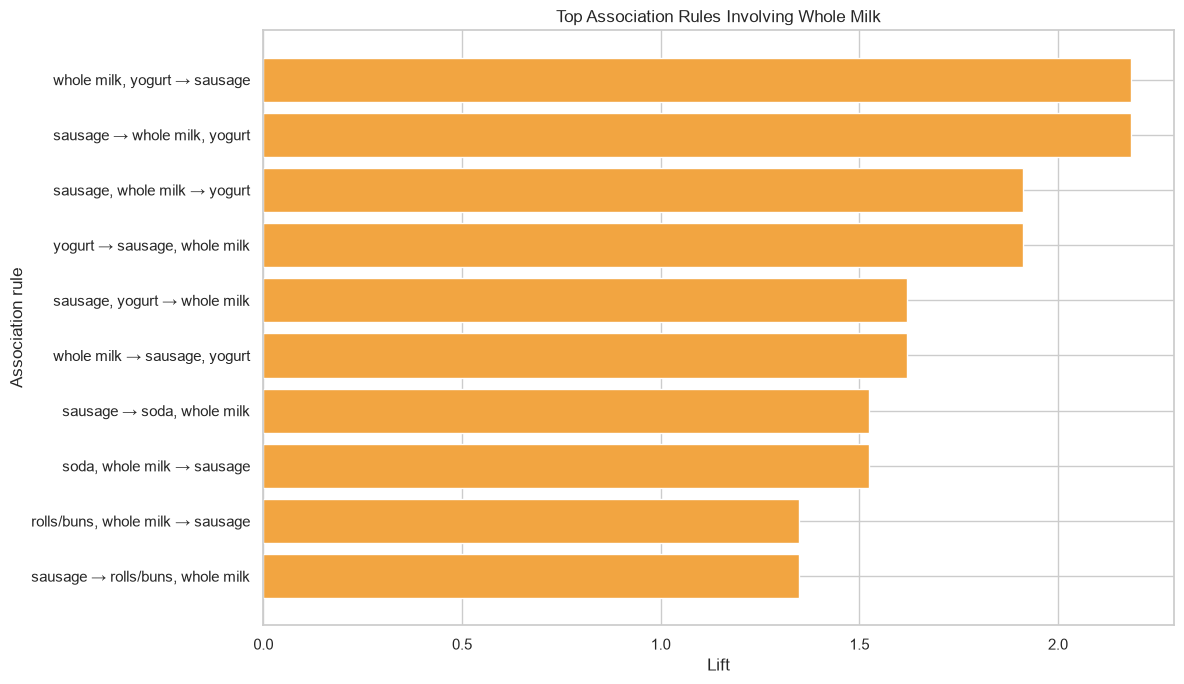

In [19]:
if not whole_milk_rules.empty:
    plot_data = whole_milk_display.sort_values("lift")
    plt.figure(figsize=(12, 7))
    plt.barh(plot_data["Rule"], plot_data["lift"], color="#F2A541")
    plt.xlabel("Lift")
    plt.ylabel("Association rule")
    plt.title("Top Association Rules Involving Whole Milk")
    plt.tight_layout()
    plt.show()


## 17. Support versus confidence

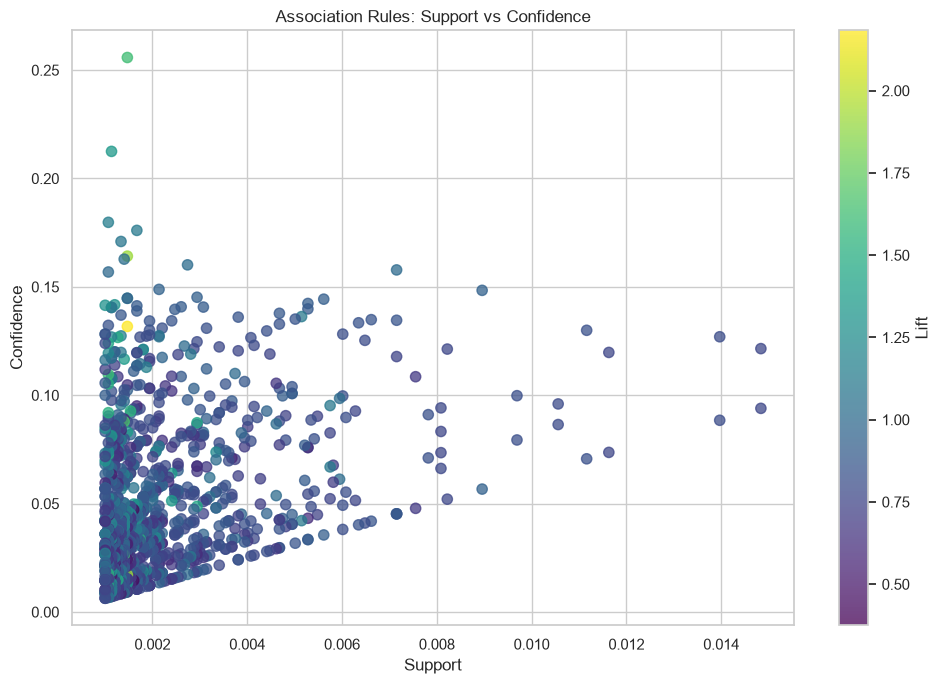

In [20]:
if not rules.empty:
    plt.figure(figsize=(10, 7))
    points = plt.scatter(rules["support"], rules["confidence"], c=rules["lift"], cmap="viridis", alpha=0.75, s=55)
    plt.colorbar(points, label="Lift")
    plt.xlabel("Support")
    plt.ylabel("Confidence")
    plt.title("Association Rules: Support vs Confidence")
    plt.tight_layout()
    plt.show()
else:
    print("No rules to plot.")


## 18. Lift versus confidence

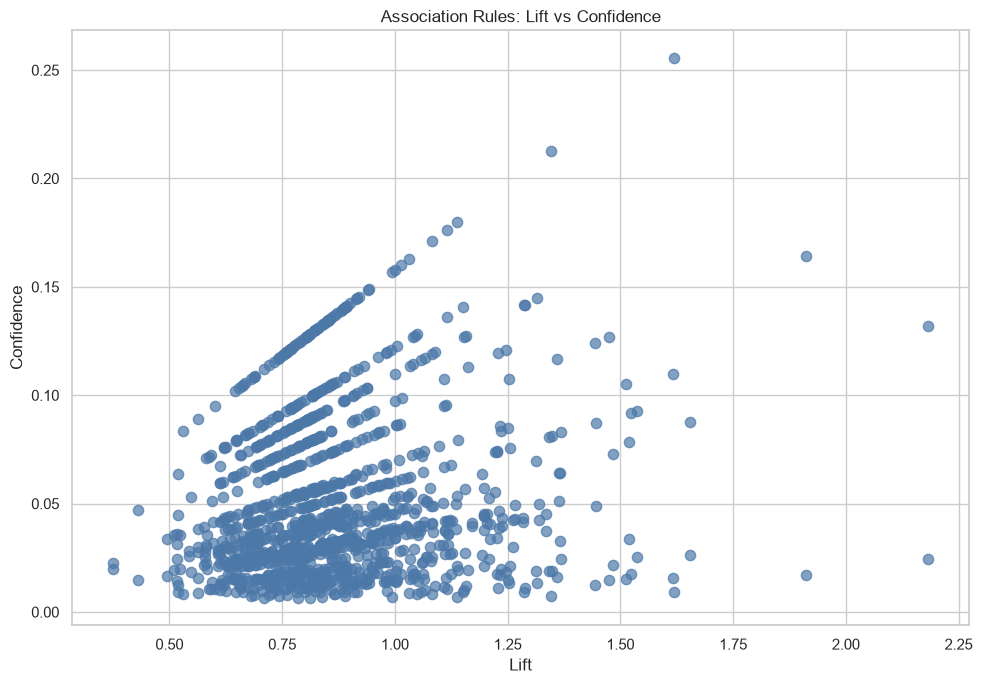

In [21]:
if not rules.empty:
    plt.figure(figsize=(10, 7))
    plt.scatter(rules["lift"], rules["confidence"], alpha=0.7, s=55, color="#4C78A8")
    plt.xlabel("Lift")
    plt.ylabel("Confidence")
    plt.title("Association Rules: Lift vs Confidence")
    plt.tight_layout()
    plt.show()
else:
    print("No rules to plot.")


## 19. Validate recommendations for one customer
For each customer-day basket, suggestions are generated from items already in that basket. This descriptive check is not a time-based predictive test.

In [22]:
customer_id = 2222
customer_baskets = df[df["Member_number"] == customer_id].sort_values("Date")
customer_validation_rows = []
if customer_baskets.empty:
    print(f"Customer {customer_id} was not found. Choose an ID from df['Member_number'].")
else:
    for basket_id, group in customer_baskets.groupby("Basket_ID"):
        bought = set(group["itemDescription"])
        suggested = set()
        for item in bought:
            suggested.update(recommend_products(item, rules)["Product"].tolist())
        hits = suggested & bought
        customer_validation_rows.append({"Basket_ID": basket_id, "Items in basket": len(bought),
            "Recommendations": len(suggested), "Hits": len(hits),
            "Hit Rate (%)": 100 * len(hits) / len(suggested) if suggested else 0.0})
customer_validation_df = pd.DataFrame(customer_validation_rows)
display(customer_validation_df)


,Basket_ID,Items in basket,Recommendations,Hits,Hit Rate (%)
0,2222_2014-02-13,3,1,0,0.000000
1,2222_2014-02-22,2,0,0,0.000000
2,2222_2014-04-03,2,3,0,0.000000
3,2222_2014-07-31,2,1,0,0.000000
4,2222_2015-01-08,2,3,0,0.000000
5,2222_2015-07-21,4,3,1,33.333333
6,2222_2015-12-28,4,5,2,40.000000


## 20. Validate across multiple customers
This samples up to 100 customers for a quick overview. Increase `MAX_CUSTOMERS` for a broader evaluation.

In [23]:
MAX_CUSTOMERS = 100
customer_ids = df["Member_number"].drop_duplicates().head(MAX_CUSTOMERS).tolist()
validation_rows = []
for customer in customer_ids:
    cust = df[df["Member_number"] == customer]
    for basket_id, group in cust.groupby("Basket_ID"):
        bought = set(group["itemDescription"])
        suggested = set()
        for item in bought:
            suggested.update(recommend_products(item, rules)["Product"].tolist())
        hits = suggested & bought
        validation_rows.append({"Member_number": customer, "Basket_ID": basket_id,
            "Items in basket": len(bought), "Recommendations": len(suggested), "Hits": len(hits),
            "Hit Rate (%)": 100 * len(hits) / len(suggested) if suggested else 0.0})
validation_df = pd.DataFrame(validation_rows)
print(f"Validated {len(validation_df):,} baskets across {len(customer_ids):,} customers.")
display(validation_df.head(20))
if not validation_df.empty:
    print("Average hit rate:", f"{validation_df['Hit Rate (%)'].mean():.2f}%")


Validated 463 baskets across 100 customers.


,Member_number,Basket_ID,Items in basket,Recommendations,Hits,Hit Rate (%)
0,1808,1808_2014-11-29,2,5,0,0.0
1,1808,1808_2014-12-15,3,0,0,0.0
2,1808,1808_2015-02-04,2,1,0,0.0
3,1808,1808_2015-07-21,3,3,0,0.0
4,2552,2552_2014-02-19,2,2,0,0.0
5,2552,2552_2014-06-20,3,4,0,0.0
6,2552,2552_2014-07-11,3,1,0,0.0
7,2552,2552_2014-10-08,2,0,0,0.0
8,2552,2552_2015-01-05,3,4,0,0.0
9,2300,2300_2014-03-16,2,1,0,0.0


Average hit rate: 5.23%


## 21. Save CSV results
The CSV files are saved in the notebook’s current working folder.

In [24]:
frequent_itemsets_to_save = frequent_itemsets.copy()
if not frequent_itemsets_to_save.empty:
    frequent_itemsets_to_save["itemsets"] = frequent_itemsets_to_save["itemsets"].apply(format_itemset)
frequent_itemsets_to_save.to_csv("frequent_itemsets.csv", index=False)
rules_display.to_csv("final_association_rules.csv", index=False)
validation_df.to_csv("customer_validation_results.csv", index=False)
print("Saved frequent_itemsets.csv, final_association_rules.csv, and customer_validation_results.csv")


Saved frequent_itemsets.csv, final_association_rules.csv, and customer_validation_results.csv


## 22. Final project summary

In [25]:
print("=" * 62)
print("ONLINE SHOPPING BASKET ANALYSIS — PROJECT SUMMARY")
print("=" * 62)
print(f"Clean purchase records : {len(df):,}")
print(f"Unique customers       : {df['Member_number'].nunique():,}")
print(f"Unique products        : {df['itemDescription'].nunique():,}")
print(f"Customer-day baskets   : {df['Basket_ID'].nunique():,}")
print(f"Frequent itemsets      : {len(frequent_itemsets):,}")
print(f"Association rules      : {len(rules):,}")
if not validation_df.empty:
    print(f"Validation baskets     : {len(validation_df):,}")
    print(f"Average hit rate       : {validation_df['Hit Rate (%)'].mean():.2f}%")
print("=" * 62)
print("Project completed successfully.")


ONLINE SHOPPING BASKET ANALYSIS — PROJECT SUMMARY
Clean purchase records : 38,006
Unique customers       : 3,898
Unique products        : 167
Customer-day baskets   : 14,963
Frequent itemsets      : 750
Association rules      : 1,238
Validation baskets     : 463
Average hit rate       : 5.23%
Project completed successfully.


## Interpreting the metrics
- **Support:** share of all baskets containing the item combination.
- **Confidence:** share of antecedent baskets that also contain the consequent.
- **Lift:** relative increase in consequent frequency when the antecedent is present.

These are co-purchase patterns and do not show that one product causes another purchase. Results are computed from your CSV when you run the notebook.
